In [86]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True

In [87]:
v = np.array([3.0, 2.0])

e1, e2 = np.array([1.0, 0.0]), np.array([0.0, 1.0])
f1, f2 = np.array([1.0, 0.0]), np.array([1.0, 1.0])
ae,be = np.linalg.solve(np.column_stack([e1,e2]), v)
print(f"базис e: ({ae:g}, {be:g})");
a, b = np.linalg.solve(np.column_stack([f1,f2]), v)
print(f"в базисе e: (3,2); в базисе f: ({a:g}, {b:g})")


базис e: (3, 2)
в базисе e: (3,2); в базисе f: (1, 2)


размер А: (600, 3)  размер ATA: (3, 3)
нормальные уравнения: [0.295  0.5094 1.9954]
np.linalg.lstsq:  [0.295  0.5094 1.9954]
настояшие [0.3, 0.5, 2.0]


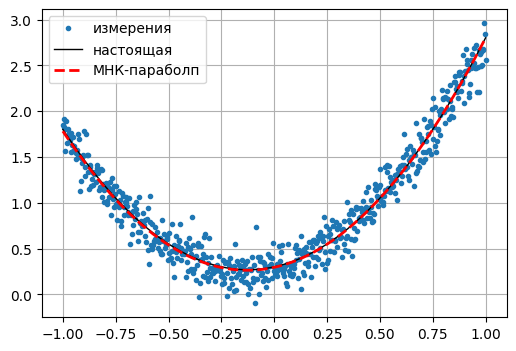

In [88]:
rng = np.random.default_rng(1)
x = np.linspace(-1, 1, 600)
true = 0.3 + 0.5 * x + 2.0 * x**2
w = true + rng.normal(0, 0.15, x.size)

A = np.column_stack([np.ones_like(x), x, x**2])
print("размер А:", A.shape, " размер ATA:", (A.T @ A).shape)

c_normal = np.linalg.solve(A.T @ A, A.T @ w)
c_lstsq, *_ = np.linalg.lstsq(A, w, rcond=None)
print("нормальные уравнения:", np.round(c_normal, 4))
print("np.linalg.lstsq: ", np.round(c_lstsq, 4))
print("настояшие", [0.3, 0.5, 2.0])


fit = A @ c_lstsq
plt.plot(x, w, ".", label="измерения")
plt.plot(x, true, "k", lw=1, label="настоящая")
plt.plot(x, fit, "r--", lw=2, label="МНК-параболп")
plt.legend();
plt.show()

In [89]:
A_leg = np.column_stack([np.ones_like(x), x, (3 * x**2 - 1) / 2])
c_leg, *_ = np.linalg.lstsq(A_leg, w, rcond=None)

print("в базисе степеней:  ", np.round(c_lstsq, 4))
print("в базисе Лежандра:  ", np.round(c_leg, 4))
print("кривые совпадают:   ", np.allclose(A @ c_lstsq, A_leg @ c_leg))

в базисе степеней:   [0.295  0.5094 1.9954]
в базисе Лежандра:   [0.9601 0.5094 1.3303]
кривые совпадают:    True


In [90]:
x = np.linspace(-1, 1, 201)
basis = {"1": np.ones_like(x), "x": x, "x^2": x**2, "x^3": x**3}
names = list(basis)
G = np.array([[np.mean(basis[a] * basis[b]) for b in names] for a in names])

print("       " + "".join )

TypeError: can only concatenate str (not "builtin_function_or_method") to str

2.49615 = 2.49615
a = [3. 1.], b = [2. 3.]
Скалярное произведение <a, b> = 9
|a| = 3.162, |b| = 3.606
cos θ = 0.789, угол θ = 37.87°
Проекция a на b = [1.38461538 2.07692308]


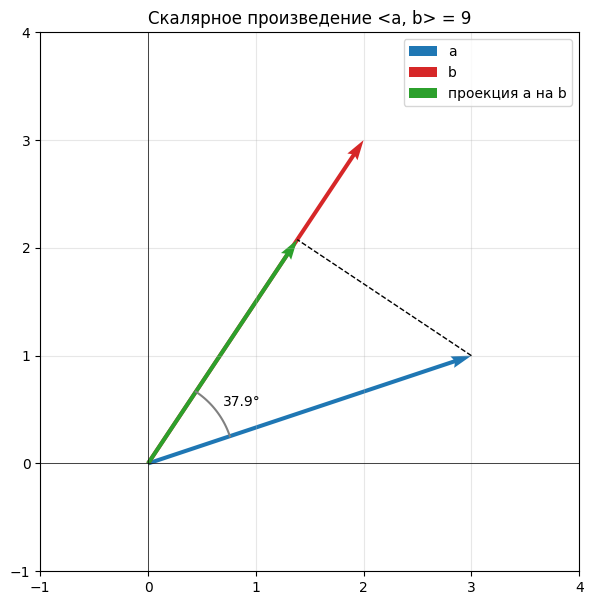

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Векторы
a = np.array([3.0, 1.0])
b = np.array([2.0, 3.0])

# Скалярное произведение: <a, b> = a1*b1 + a2*b2 = |a|·|b|·cos(θ)
dot = np.dot(a, b)

# Длины и угол между векторами
norm_a = np.linalg.norm(a)
norm_b = np.linalg.norm(b)
cos_theta = dot / (norm_a * norm_b)
theta = np.degrees(np.arccos(cos_theta))

# Проекция a на b: proj = (<a,b> / <b,b>) · b
proj = (dot / np.dot(b, b)) * b
norm_proj = np.linalg.norm(proj)

proj2 = norm_a * cos_theta

print(f"{proj2:g} = {norm_proj:g}")

print(f"a = {a}, b = {b}")
print(f"Скалярное произведение <a, b> = {dot:g}")
print(f"|a| = {norm_a:.3f}, |b| = {norm_b:.3f}")
print(f"cos θ = {cos_theta:.3f}, угол θ = {theta:.2f}°")
print(f"Проекция a на b = {proj}")

# --- График ---
fig, ax = plt.subplots(figsize=(7, 7))

def draw(v, color, label, style="-"):
    ax.quiver(0, 0, v[0], v[1], angles="xy", scale_units="xy", scale=1,
              color=color, label=label, linestyle=style)

draw(a, "tab:blue", "a")
draw(b, "tab:red", "b")
draw(proj, "tab:green", "проекция a на b")

# Пунктир от конца a до его проекции на b (перпендикуляр)
ax.plot([a[0], proj[0]], [a[1], proj[1]], "k--", linewidth=1)

# Дуга угла между векторами
ang_a = np.arctan2(a[1], a[0])
ang_b = np.arctan2(b[1], b[0])
t = np.linspace(min(ang_a, ang_b), max(ang_a, ang_b), 50)
r = 0.8
ax.plot(r * np.cos(t), r * np.sin(t), color="gray")
mid = (ang_a + ang_b) / 2
ax.text(1.1 * r * np.cos(mid), 1.1 * r * np.sin(mid), f"{theta:.1f}°")

ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.set_aspect("equal")
ax.axhline(0, color="black", linewidth=0.5)
ax.axvline(0, color="black", linewidth=0.5)
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_title(f"Скалярное произведение <a, b> = {dot:g}")
plt.show()



3.0, 1.0


4.0, 1.0
[5. 3.] = [5 3]


G^-1 =
 [[ 0.5  0.5]
 [ 0.5 -0.5]]
G^-1 @ v = [4. 1.]


In [ ]:
a = np.array([2,1])
b = np.array([-1,3])

dot = np.dot(a,b)
norm_a = np.linalg.norm(a)
norm_b = np.linalg.norm(b)

cos_theta = np.dot(a,b)/(norm_a * norm_b)
theta = np.arccos(cos_theta)


пиксели внутри круга: 70681


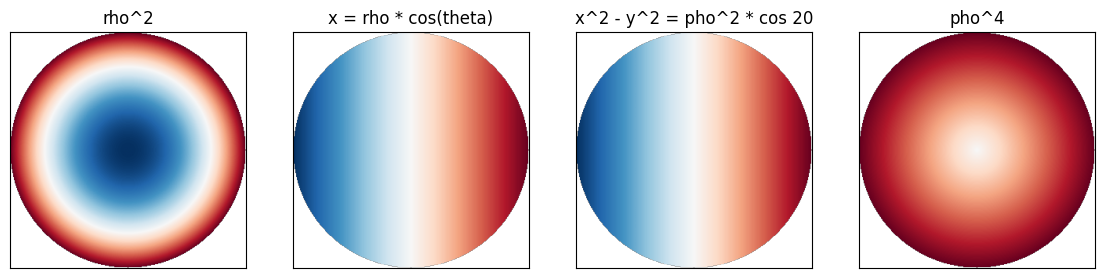

In [ ]:
n = 301
u = np.linspace(-1,1,n)
X,Y = np.meshgrid(u, -u)
R = np.hypot(X,Y)
inside = R <= 1

x, y = X[inside], Y[inside]
rho, theta = R[inside], np.arctan2(y, x)
print("пиксели внутри круга:", inside.sum())

def ip(f, g):
  return np.mean(f*g)

def show(values, ax, title, vmax = None):
  # Вернуть значения пикселей круга обратно в квадратную картинку
  img = np.full(X.shape, np.nan)
  img[inside] = values
  if vmax is None:
    vmax = np.nanmax(np.abs(img))
  im = ax.imshow(img, extent=(-1, 1, -1, 1), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
  ax.set_title(title);
  ax.set_xticks([])
  ax.set_yticks([])
  return im

fig, axes = plt.subplots(1, 4, figsize = (14, 3.5))
show(rho**2-1/2, axes[0], "rho^2")
show(x, axes[1], "x = rho * cos(theta)")
show(rho * np.cos(theta), axes[2], "x^2 - y^2 = pho^2 * cos 20")
show(rho, axes[3], "pho^4")
plt.show()
a = ip(rho**2-1/2,1)




среднее x^2 на отрезке:  0.3333
среднее rho^2 по кругу:  0.5
rho mean 0.5


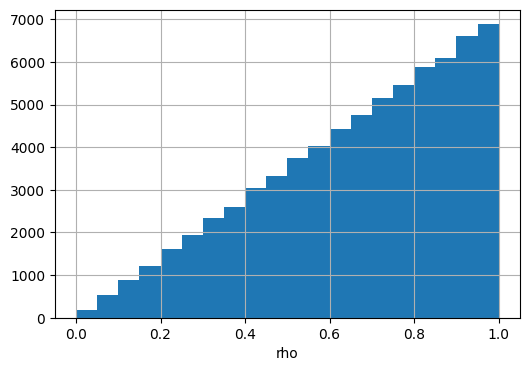

In [ ]:
print("среднее x^2 на отрезке: ", round(np.mean(np.linspace(-1,1,100001)**2), 4))
print("среднее rho^2 по кругу: ", round(ip(rho**2, 1), 4))
print("rho mean", round(np.mean(rho**2), 4))

plt.hist(rho, bins=20)
plt.xlabel("rho")
plt.show()

In [ ]:
terms = {
  "1": np.ones_like(rho),
  "x": x, "y":y,
  "rho^2":rho**2,
  "x^2-y":x**2 -y**2, "2xy":2*x*y,
  "rho^4":rho**4,
}
names = list(terms)
G = np.array([[ip(terms[a], terms[b]) for b in names] for a in names])
print("       " + "".join(f"{n:>7}" for n in names))
for n, row in zip(names, G):
    print(f"{n:>7}" + "".join(f"{v:7.3f}" for v in row))


             1      x      y  rho^2  x^2-y    2xy  rho^4
      1  1.000  0.000 -0.000  0.500 -0.000 -0.000  0.333
      x  0.000  0.250 -0.000  0.000  0.000 -0.000  0.000
      y -0.000 -0.000  0.250 -0.000  0.000  0.000 -0.000
  rho^2  0.500  0.000 -0.000  0.333 -0.000 -0.000  0.250
  x^2-y -0.000  0.000  0.000 -0.000  0.166  0.000  0.000
    2xy -0.000 -0.000  0.000 -0.000  0.000  0.167  0.000
  rho^4  0.333  0.000 -0.000  0.250  0.000  0.000  0.200


In [ ]:
def project_out(f, others):
  for g in others:
    f = f - (ip(f, g) / ip(g, g))*g
  return f

one = np.ones_like(rho)
Q1 = project_out(rho**2, [one])
Q2 = project_out(rho**4, [one, Q1])

monomials = np.column_stack([one, rho**2, rho**4])
for name, Q in [("Q1", Q1), ("Q2", Q2)]:
  c = np.linalg.lstsq(monomials, Q, rcond=None)[0]
  print(f"{name} = {c[2]:+.3f}·ρ⁴ {c[1]:+.3f}·ρ² {c[0]:+.3f}")

Q1 = +0.000·ρ⁴ +1.000·ρ² -0.500
Q2 = +1.000·ρ⁴ -1.000·ρ² +0.167


In [92]:
n = 301
u = np.linspace(-1,1,n)
X,Y = np.meshgrid(u,-u)
R = np.hypot(X,Y)
inside = R <= 1
rho = R[inside]

W = 0.3 * (6 * rho**4 - 6*rho**2 +1)

def Z20(r): return 2*r**2 - 1
def Z40(r): return 6*r**3 - 6*r**2+1

def fit(s):
  r = rho/s
  A = np.column_stack([np.ones_like(r), Z20(r), Z40(r)])
  c = np.linalg.lstsq(A, W, rcond=None)[0]
  resid = W - A @ c
  return c, np.sqrt(np.mean(resid**2))

for s in (1.0, 1.05):
  c, rms = fit(s)
  print(f"радиус {s}:  1 = {c[0]:+.4f}   Z20 = {c[1]:+.4f}   Z40 = {c[2]:+.4f}   СКО остатка = {rms:.1e}")



радиус 1.0:  1 = -0.2074   Z20 = -0.0444   Z40 = +0.5185   СКО остатка = 1.5e-02
радиус 1.05:  1 = -0.2079   Z20 = +0.0367   Z40 = +0.6002   СКО остатка = 1.5e-02
